# Notebook 2 — Barnes–Hut Tree Code para a minigaláxia

## Força aproximada, convergência e aumento de resolução

Este notebook começa um estudo novo. O notebook da minigaláxia com soma direta permanece fechado como referência.

O objetivo aqui é implementar um **quadtree Barnes–Hut 2D**, validar suas forças contra a soma direta e permitir simulações com milhares ou dezenas de milhares de superpartículas.

### Princípio de organização

As duas estratégias são completamente independentes:

| Rota | Arquivo numérico | GIF |
|---|---|---|
| Soma direta | `resultado_direct_...npz` | GIF somente da soma direta |
| Barnes–Hut | `resultado_tree_...npz` | GIF somente do Tree Code |
| Comparação | Carrega os dois arquivos | GIF com duas colunas |

Alterar o número de partículas do Tree Code **não recalcula nem sobrescreve** o caso direto. O GIF comparativo também não executa simulações: ele apenas carrega resultados existentes.

> CPU é suficiente. O Numba é importante; GPU não é utilizada.


## 1. Como usar sem recalcular o que já existe

1. Execute as células de definições e configurações.
2. Na seção desejada, altere apenas `EXECUTAR_DIRETO` **ou** `EXECUTAR_TREE` para `True`.
3. O resultado será salvo em `.npz` com método, \(N\), \(\epsilon\), \(\theta\), passo temporal e semente no nome.
4. Volte a colocar o controle em `False` depois da execução.
5. Gere cada GIF em sua própria célula.

Se utilizar Google Drive, os resultados sobrevivem ao encerramento do ambiente Colab. Sem Drive, eles permanecem apenas durante a sessão.


In [1]:
import json
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np


try:
    from numba import njit

    NUMBA_AVAILABLE = True
except ImportError:
    NUMBA_AVAILABLE = False

    def njit(*args, **kwargs):
        if args and callable(args[0]) and len(args) == 1 and not kwargs:
            return args[0]

        def decorator(func):
            return func

        return decorator


G = 4.498502151575286e-12  # kpc^3 / (Msun Myr^2)
KPC_MYR_TO_KM_S = 977.79222168


@dataclass(frozen=True)
class SimulationConfig:
    n: int = 1500
    m_halo: float = 2.0e11
    a_halo: float = 6.0
    m_disk: float = 4.0e10
    r_disk: float = 3.0
    r_max: float = 15.0
    epsilon: float = 0.50
    dt: float = 0.50
    t_end: float = 500.0
    record_every: int = 10
    seed: int = 20261027
    theta: float = 0.50
    bucket_capacity: int = 8
    max_depth: int = 48


def sample_exponential_disk(cfg):
    rng = np.random.default_rng(cfg.seed)
    radii = []
    while len(radii) < cfg.n:
        draw = rng.gamma(shape=2.0, scale=cfg.r_disk, size=2 * cfg.n)
        accepted = draw[(draw >= 0.35) & (draw <= cfg.r_max)]
        radii.extend(accepted.tolist())

    r = np.asarray(radii[: cfg.n], dtype=np.float64)
    theta = rng.uniform(0.0, 2.0 * np.pi, cfg.n)
    pos = np.column_stack((r * np.cos(theta), r * np.sin(theta)))

    er = pos / r[:, None]
    et = np.column_stack((-er[:, 1], er[:, 0]))
    vc2_halo = G * cfg.m_halo * r**2 / (r**2 + cfg.a_halo**2) ** 1.5
    x = r / cfg.r_disk
    enclosed_disk = cfg.m_disk * (1.0 - np.exp(-x) * (1.0 + x))
    vc = np.sqrt(np.maximum(vc2_halo + G * enclosed_disk / r, 0.0))

    sigma = 0.025 * vc
    v_radial = rng.normal(0.0, sigma)
    v_tangent = vc + rng.normal(0.0, sigma)
    vel = v_radial[:, None] * er + v_tangent[:, None] * et
    vel -= np.mean(vel, axis=0, keepdims=True)
    return pos, vel


def halo_acceleration_and_potential(pos, m_halo, a_halo):
    r2 = np.sum(pos * pos, axis=1)
    denom = np.sqrt(r2 + a_halo * a_halo)
    acc = -G * m_halo * pos / denom[:, None] ** 3
    phi = -G * m_halo / denom
    return acc, phi

import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.20})


## 2. Soma direta — referência \(O(N^2)\)

A soma direta calcula todas as interações e continuará sendo nossa referência para erros de força e simulações com \(N\) moderado.


In [2]:
@njit
def _direct_disk_force_loop(pos, particle_mass, epsilon):
    n = pos.shape[0]
    acc = np.zeros((n, 2), dtype=np.float64)
    phi = np.zeros(n, dtype=np.float64)
    eps2 = epsilon * epsilon
    for i in range(n):
        ax = 0.0
        ay = 0.0
        potential = 0.0
        xi = pos[i, 0]
        yi = pos[i, 1]
        for j in range(n):
            if i == j:
                continue
            dx = pos[j, 0] - xi
            dy = pos[j, 1] - yi
            d2 = dx * dx + dy * dy + eps2
            distance = np.sqrt(d2)
            inv_r3 = 1.0 / (d2 * distance)
            ax += G * particle_mass * dx * inv_r3
            ay += G * particle_mass * dy * inv_r3
            potential -= G * particle_mass / distance
        acc[i, 0] = ax
        acc[i, 1] = ay
        phi[i] = potential
    return acc, phi


def _direct_disk_force_numpy(pos, particle_mass, epsilon):
    delta = pos[None, :, :] - pos[:, None, :]
    dist2 = np.sum(delta * delta, axis=2) + epsilon * epsilon
    inv_r3 = dist2 ** -1.5
    inv_r = dist2 ** -0.5
    np.fill_diagonal(inv_r3, 0.0)
    np.fill_diagonal(inv_r, 0.0)
    acc = G * particle_mass * np.sum(delta * inv_r3[:, :, None], axis=1)
    phi = -G * particle_mass * np.sum(inv_r, axis=1)
    return acc, phi


def direct_disk_force(pos, particle_mass, epsilon):
    if NUMBA_AVAILABLE:
        return _direct_disk_force_loop(pos, particle_mass, epsilon)
    return _direct_disk_force_numpy(pos, particle_mass, epsilon)


## 3. Barnes–Hut com quadtree

O domínio é subdividido adaptativamente em quatro células. Cada nó armazena massa total e centro de massa.

Uma célula de largura \(s\), observada a uma distância \(d\), é aproximada por uma única massa quando

\[
\frac{s}{d}<\theta.
\]

- \(\theta\) pequeno: maior precisão e maior custo;
- \(\theta\) grande: menor custo e maior erro.

Folhas próximas são calculadas diretamente. O parâmetro `bucket_capacity` controla quantas partículas podem permanecer em uma folha antes de sua subdivisão.


In [3]:
@njit
def _quadrant(x, y, center_x, center_y):
    q = 0
    if x >= center_x:
        q += 1
    if y >= center_y:
        q += 2
    return q


@njit
def _build_quadtree(pos, particle_mass, bucket_capacity, max_depth):
    n = pos.shape[0]
    max_nodes = max(32, 8 * n + 1)

    children = np.full((max_nodes, 4), -1, dtype=np.int64)
    is_leaf = np.ones(max_nodes, dtype=np.uint8)
    head = np.full(max_nodes, -1, dtype=np.int64)
    count = np.zeros(max_nodes, dtype=np.int64)
    next_particle = np.full(n, -1, dtype=np.int64)

    center_x = np.zeros(max_nodes, dtype=np.float64)
    center_y = np.zeros(max_nodes, dtype=np.float64)
    half_size = np.zeros(max_nodes, dtype=np.float64)
    mass = np.zeros(max_nodes, dtype=np.float64)
    com_x = np.zeros(max_nodes, dtype=np.float64)
    com_y = np.zeros(max_nodes, dtype=np.float64)

    xmin = np.min(pos[:, 0])
    xmax = np.max(pos[:, 0])
    ymin = np.min(pos[:, 1])
    ymax = np.max(pos[:, 1])
    span = max(xmax - xmin, ymax - ymin)
    center_x[0] = 0.5 * (xmin + xmax)
    center_y[0] = 0.5 * (ymin + ymax)
    half_size[0] = 0.5 * span * (1.0 + 1.0e-12) + 1.0e-12
    node_count = 1

    for particle in range(n):
        node = 0
        depth = 0
        while True:
            if is_leaf[node] == 1:
                if count[node] < bucket_capacity or depth >= max_depth:
                    next_particle[particle] = head[node]
                    head[node] = particle
                    count[node] += 1
                    break

                if node_count + 4 > max_nodes:
                    raise RuntimeError("Quadtree excedeu o número máximo de nós")

                # Divide a folha e cria os quatro filhos.
                is_leaf[node] = 0
                child_half = 0.5 * half_size[node]
                for q in range(4):
                    child = node_count
                    node_count += 1
                    children[node, q] = child
                    half_size[child] = child_half
                    center_x[child] = center_x[node] + (child_half if (q & 1) else -child_half)
                    center_y[child] = center_y[node] + (child_half if (q & 2) else -child_half)

                # Redistribui as partículas que estavam na folha.
                old_particle = head[node]
                head[node] = -1
                count[node] = 0
                while old_particle != -1:
                    following = next_particle[old_particle]
                    q_old = _quadrant(
                        pos[old_particle, 0],
                        pos[old_particle, 1],
                        center_x[node],
                        center_y[node],
                    )
                    child = children[node, q_old]
                    next_particle[old_particle] = head[child]
                    head[child] = old_particle
                    count[child] += 1
                    old_particle = following
                # Continua no mesmo nó, agora interno, para inserir a partícula atual.
            else:
                q = _quadrant(
                    pos[particle, 0], pos[particle, 1], center_x[node], center_y[node]
                )
                node = children[node, q]
                depth += 1

    # Massas e centros de massa: filhos sempre possuem índices maiores que o pai.
    for node in range(node_count - 1, -1, -1):
        if is_leaf[node] == 1:
            particle = head[node]
            total_mass = 0.0
            weighted_x = 0.0
            weighted_y = 0.0
            while particle != -1:
                total_mass += particle_mass
                weighted_x += particle_mass * pos[particle, 0]
                weighted_y += particle_mass * pos[particle, 1]
                particle = next_particle[particle]
            mass[node] = total_mass
            if total_mass > 0.0:
                com_x[node] = weighted_x / total_mass
                com_y[node] = weighted_y / total_mass
        else:
            total_mass = 0.0
            weighted_x = 0.0
            weighted_y = 0.0
            for q in range(4):
                child = children[node, q]
                child_mass = mass[child]
                total_mass += child_mass
                weighted_x += child_mass * com_x[child]
                weighted_y += child_mass * com_y[child]
            mass[node] = total_mass
            if total_mass > 0.0:
                com_x[node] = weighted_x / total_mass
                com_y[node] = weighted_y / total_mass

    return (
        children,
        is_leaf,
        head,
        next_particle,
        center_x,
        center_y,
        half_size,
        mass,
        com_x,
        com_y,
        node_count,
    )


@njit
def _tree_disk_force_core(
    pos, particle_mass, epsilon, theta, bucket_capacity, max_depth
):
    (
        children,
        is_leaf,
        head,
        next_particle,
        center_x,
        center_y,
        half_size,
        mass,
        com_x,
        com_y,
        node_count,
    ) = _build_quadtree(pos, particle_mass, bucket_capacity, max_depth)

    n = pos.shape[0]
    acc = np.zeros((n, 2), dtype=np.float64)
    phi = np.zeros(n, dtype=np.float64)
    eps2 = epsilon * epsilon
    stack = np.empty(node_count, dtype=np.int64)

    for i in range(n):
        stack_size = 1
        stack[0] = 0
        ax = 0.0
        ay = 0.0
        potential = 0.0
        xi = pos[i, 0]
        yi = pos[i, 1]

        while stack_size > 0:
            stack_size -= 1
            node = stack[stack_size]
            if mass[node] <= 0.0:
                continue

            if is_leaf[node] == 1:
                j = head[node]
                while j != -1:
                    if j != i:
                        dx = pos[j, 0] - xi
                        dy = pos[j, 1] - yi
                        d2 = dx * dx + dy * dy + eps2
                        distance = np.sqrt(d2)
                        inv_r3 = 1.0 / (d2 * distance)
                        ax += G * particle_mass * dx * inv_r3
                        ay += G * particle_mass * dy * inv_r3
                        potential -= G * particle_mass / distance
                    j = next_particle[j]
                continue

            dx = com_x[node] - xi
            dy = com_y[node] - yi
            distance_geom = np.sqrt(dx * dx + dy * dy) + 1.0e-30
            contains_target = (
                abs(xi - center_x[node]) <= half_size[node]
                and abs(yi - center_y[node]) <= half_size[node]
            )
            accept = (not contains_target) and (2.0 * half_size[node] / distance_geom < theta)

            if accept:
                d2 = dx * dx + dy * dy + eps2
                distance = np.sqrt(d2)
                inv_r3 = 1.0 / (d2 * distance)
                ax += G * mass[node] * dx * inv_r3
                ay += G * mass[node] * dy * inv_r3
                potential -= G * mass[node] / distance
            else:
                for q in range(4):
                    child = children[node, q]
                    if child >= 0 and mass[child] > 0.0:
                        stack[stack_size] = child
                        stack_size += 1

        acc[i, 0] = ax
        acc[i, 1] = ay
        phi[i] = potential

    return acc, phi, node_count


def tree_disk_force(pos, particle_mass, epsilon, theta, bucket_capacity=8, max_depth=48):
    if not NUMBA_AVAILABLE and pos.shape[0] > 2000:
        raise RuntimeError("Para N>2000, execute o Tree Code em um ambiente com Numba.")
    return _tree_disk_force_core(
        pos, particle_mass, epsilon, theta, bucket_capacity, max_depth
    )


## 4. Leapfrog, diagnósticos e arquivos independentes

As duas rotas utilizam as mesmas condições iniciais e o mesmo Leapfrog kick–drift–kick. São armazenados:

- posições para os GIFs;
- energia e momento angular;
- \(r_{10},r_{50},r_{90}\);
- frações além de 15 e 20 kpc;
- modos azimutais \(A_1\) e \(A_2\);
- quantidade de nós da árvore.


In [4]:
def total_force(pos, cfg, method):
    particle_mass = cfg.m_disk / cfg.n
    halo_acc, halo_phi = halo_acceleration_and_potential(pos, cfg.m_halo, cfg.a_halo)
    if method == "direct":
        disk_acc, disk_phi = direct_disk_force(pos, particle_mass, cfg.epsilon)
        node_count = 0
    elif method == "tree":
        disk_acc, disk_phi, node_count = tree_disk_force(
            pos,
            particle_mass,
            cfg.epsilon,
            cfg.theta,
            cfg.bucket_capacity,
            cfg.max_depth,
        )
    else:
        raise ValueError("method deve ser 'direct' ou 'tree'")
    return halo_acc + disk_acc, halo_phi, disk_phi, node_count


def compute_diagnostics(pos, vel, halo_phi, disk_phi, cfg):
    particle_mass = cfg.m_disk / cfg.n
    kinetic = 0.5 * particle_mass * np.sum(vel * vel)
    potential_halo = particle_mass * np.sum(halo_phi)
    potential_disk = 0.5 * particle_mass * np.sum(disk_phi)
    energy = kinetic + potential_halo + potential_disk
    lz = particle_mass * np.sum(pos[:, 0] * vel[:, 1] - pos[:, 1] * vel[:, 0])
    radius = np.linalg.norm(pos, axis=1)
    angle = np.arctan2(pos[:, 1], pos[:, 0])
    a1 = abs(np.mean(np.exp(1j * angle)))
    a2 = abs(np.mean(np.exp(2j * angle)))
    return (
        energy,
        lz,
        np.quantile(radius, [0.1, 0.5, 0.9]),
        np.mean(radius > 15.0),
        np.mean(radius > 20.0),
        a1,
        a2,
    )


def run_simulation(cfg, method, progress_every=100):
    pos, vel = sample_exponential_disk(cfg)
    n_steps = int(round(cfg.t_end / cfg.dt))
    records = {
        "time": [],
        "positions": [],
        "energy": [],
        "lz": [],
        "r_quantiles": [],
        "frac_gt15": [],
        "frac_gt20": [],
        "a1": [],
        "a2": [],
        "node_count": [],
    }

    def record(step, halo_phi, disk_phi, node_count):
        values = compute_diagnostics(pos, vel, halo_phi, disk_phi, cfg)
        records["time"].append(step * cfg.dt)
        records["positions"].append(pos.astype(np.float32))
        records["energy"].append(values[0])
        records["lz"].append(values[1])
        records["r_quantiles"].append(values[2])
        records["frac_gt15"].append(values[3])
        records["frac_gt20"].append(values[4])
        records["a1"].append(values[5])
        records["a2"].append(values[6])
        records["node_count"].append(node_count)

    start = time.perf_counter()
    acc, halo_phi, disk_phi, node_count = total_force(pos, cfg, method)
    record(0, halo_phi, disk_phi, node_count)

    for step in range(1, n_steps + 1):
        vel_half = vel + 0.5 * cfg.dt * acc
        pos = pos + cfg.dt * vel_half
        acc_new, halo_phi, disk_phi, node_count = total_force(pos, cfg, method)
        vel = vel_half + 0.5 * cfg.dt * acc_new
        acc = acc_new

        if step % cfg.record_every == 0 or step == n_steps:
            record(step, halo_phi, disk_phi, node_count)
        if progress_every and step % progress_every == 0:
            print(f"{method}: passo {step}/{n_steps}")

    result = {key: np.asarray(value) for key, value in records.items()}
    result["runtime"] = np.asarray(time.perf_counter() - start)
    result["method"] = np.asarray(method)
    result["config_json"] = np.asarray(json.dumps(asdict(cfg)))
    return result


def result_filename(method, cfg):
    theta_part = f"_theta{cfg.theta:.2f}" if method == "tree" else ""
    return (
        f"resultado_{method}_N{cfg.n}{theta_part}_eps{cfg.epsilon:.2f}"
        f"_dt{cfg.dt:.2f}_T{cfg.t_end:.0f}_seed{cfg.seed}.npz"
    )


def save_result(result, path):
    path = Path(path)
    np.savez_compressed(path, **result)
    return path


def load_result(path):
    with np.load(path, allow_pickle=False) as data:
        return {key: data[key] for key in data.files}


In [5]:
def force_comparison(cfg, theta_values=(0.3, 0.5, 0.7, 1.0)):
    pos, _ = sample_exponential_disk(cfg)
    particle_mass = cfg.m_disk / cfg.n

    start = time.perf_counter()
    acc_direct, _ = direct_disk_force(pos, particle_mass, cfg.epsilon)
    direct_time = time.perf_counter() - start

    rows = []
    direct_norm = np.linalg.norm(acc_direct, axis=1)
    scale = max(np.median(direct_norm) * 1.0e-12, 1.0e-30)
    for theta in theta_values:
        start = time.perf_counter()
        acc_tree, _, node_count = tree_disk_force(
            pos,
            particle_mass,
            cfg.epsilon,
            theta,
            cfg.bucket_capacity,
            cfg.max_depth,
        )
        tree_time = time.perf_counter() - start
        relative = np.linalg.norm(acc_tree - acc_direct, axis=1) / (direct_norm + scale)
        rows.append(
            {
                "theta": theta,
                "median": float(np.median(relative)),
                "p95": float(np.quantile(relative, 0.95)),
                "maximum": float(np.max(relative)),
                "direct_time": direct_time,
                "tree_time": tree_time,
                "speedup": direct_time / tree_time,
                "node_count": int(node_count),
            }
        )
    return rows


## 5. Pasta de resultados


In [6]:
import sys
from dataclasses import replace

USE_GOOGLE_DRIVE = False

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/Astrofisica/BarnesHut")
else:
    base = Path("/content") if "google.colab" in sys.modules else Path.cwd()
    OUTPUT_DIR = base / "BarnesHut_outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Resultados serão armazenados em:", OUTPUT_DIR)


Resultados serão armazenados em: BarnesHut_outputs


## 6. Configurações independentes

Há três configurações:

- `DIRECT_CFG`: referência com 1.500 partículas;
- `TREE_VALIDATION_CFG`: Barnes–Hut com exatamente a mesma configuração, para comparação justa;
- `TREE_HIGHRES_CFG`: produção com 10.000 partículas.

Escolha qual configuração do Tree Code será executada atribuindo-a a `TREE_CFG`. Isso não altera `DIRECT_CFG`.


In [7]:
DIRECT_CFG = SimulationConfig(
    n=1500,
    epsilon=0.50,
    dt=0.50,
    t_end=500.0,
    record_every=10,
    seed=20261027,
)

TREE_VALIDATION_CFG = replace(
    DIRECT_CFG,
    theta=0.50,
)

TREE_HIGHRES_CFG = SimulationConfig(
    n=10_000,
    epsilon=0.20,
    theta=0.50,
    dt=0.50,
    t_end=500.0,
    record_every=10,
    seed=20261027,
    bucket_capacity=8,
)

# Escolha somente uma destas linhas:
# TREE_CFG = TREE_VALIDATION_CFG
TREE_CFG = TREE_HIGHRES_CFG

DIRECT_RESULT_PATH = OUTPUT_DIR / result_filename("direct", DIRECT_CFG)
TREE_RESULT_PATH = OUTPUT_DIR / result_filename("tree", TREE_CFG)

print("Direta:", DIRECT_RESULT_PATH.name)
print("Tree:  ", TREE_RESULT_PATH.name)


Direta: resultado_direct_N1500_eps0.50_dt0.50_T500_seed20261027.npz
Tree:   resultado_tree_N10000_theta0.50_eps0.20_dt0.50_T500_seed20261027.npz


In [8]:
def list_saved_results():
    files = sorted(OUTPUT_DIR.glob("resultado_*.npz"))
    if not files:
        print("Nenhum resultado salvo ainda.")
        return []
    for path in files:
        size_mb = path.stat().st_size / 1024**2
        print(f"{path.name}  ({size_mb:.1f} MB)")
    return files


list_saved_results()


Nenhum resultado salvo ainda.


## 7. Aquecimento do Numba

Esta célula compila os núcleos numéricos usando um sistema pequeno. O tempo de compilação não será confundido com o tempo físico das simulações ou do benchmark.


In [9]:
def warmup_numba():
    cfg = SimulationConfig(n=32, t_end=1.0)
    pos, _ = sample_exponential_disk(cfg)
    mass = cfg.m_disk / cfg.n
    direct_disk_force(pos, mass, cfg.epsilon)
    tree_disk_force(
        pos, mass, cfg.epsilon, cfg.theta,
        cfg.bucket_capacity, cfg.max_depth,
    )
    print("Núcleos preparados. Numba disponível:", NUMBA_AVAILABLE)


warmup_numba()


Núcleos preparados. Numba disponível: False


## 8. Visualização do quadtree


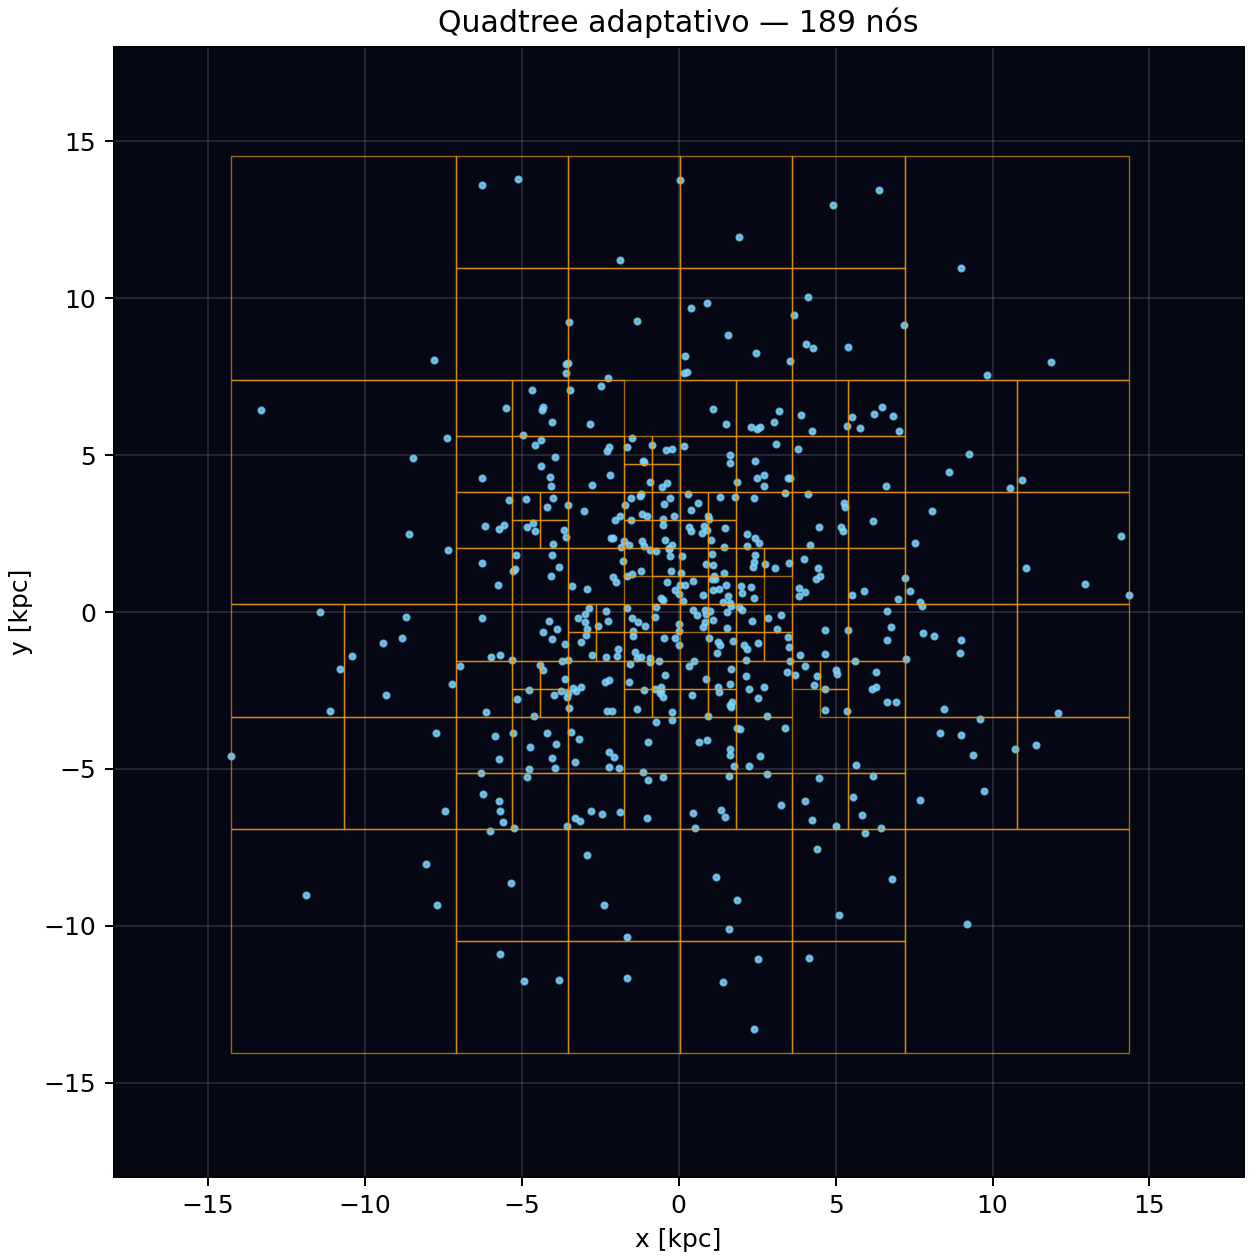

In [10]:
from matplotlib.patches import Rectangle


def plot_quadtree(cfg, n_visual=500):
    visual_cfg = replace(cfg, n=n_visual, t_end=1.0)
    pos, _ = sample_exponential_disk(visual_cfg)
    tree = _build_quadtree(
        pos,
        visual_cfg.m_disk / visual_cfg.n,
        visual_cfg.bucket_capacity,
        visual_cfg.max_depth,
    )
    (
        children, is_leaf, head, next_particle,
        center_x, center_y, half_size, mass,
        com_x, com_y, node_count,
    ) = tree

    fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
    ax.scatter(pos[:, 0], pos[:, 1], s=5, c="#7dd3fc", alpha=0.8)
    for node in range(node_count):
        if is_leaf[node] == 1 and mass[node] > 0.0:
            h = half_size[node]
            ax.add_patch(Rectangle(
                (center_x[node] - h, center_y[node] - h),
                2*h, 2*h, fill=False,
                edgecolor="#f59e0b", linewidth=0.55, alpha=0.65,
            ))
    ax.set(
        xlim=(-18, 18), ylim=(-18, 18), aspect="equal",
        xlabel="x [kpc]", ylabel="y [kpc]",
        title=f"Quadtree adaptativo — {node_count} nós",
    )
    ax.set_facecolor("#050814")
    ax.grid(alpha=0.18)
    return fig


fig = plot_quadtree(TREE_VALIDATION_CFG, n_visual=500)
plt.show()


## 9. Validação instantânea das forças

Esta etapa é barata: ela calcula apenas uma avaliação de força direta e uma avaliação Barnes–Hut para cada \(\theta\). Não executa uma simulação completa.

O erro de cada partícula é

\[
\delta a_i=
\frac{\|\mathbf a_i^{BH}-\mathbf a_i^{direta}\|}
{\|\mathbf a_i^{direta}\|+\varepsilon_{num}}.
\]


 theta      mediana          p95       máximo   tempo tree [s]
  0.30   1.1992e-03   3.1194e-03   4.7454e-03           0.4554
  0.50   8.6496e-03   1.5327e-02   3.2193e-02           0.2981
  0.70   2.1551e-02   4.4456e-02   8.5853e-02           0.1773
  1.00   5.1132e-02   1.0795e-01   2.9470e-01           0.1118


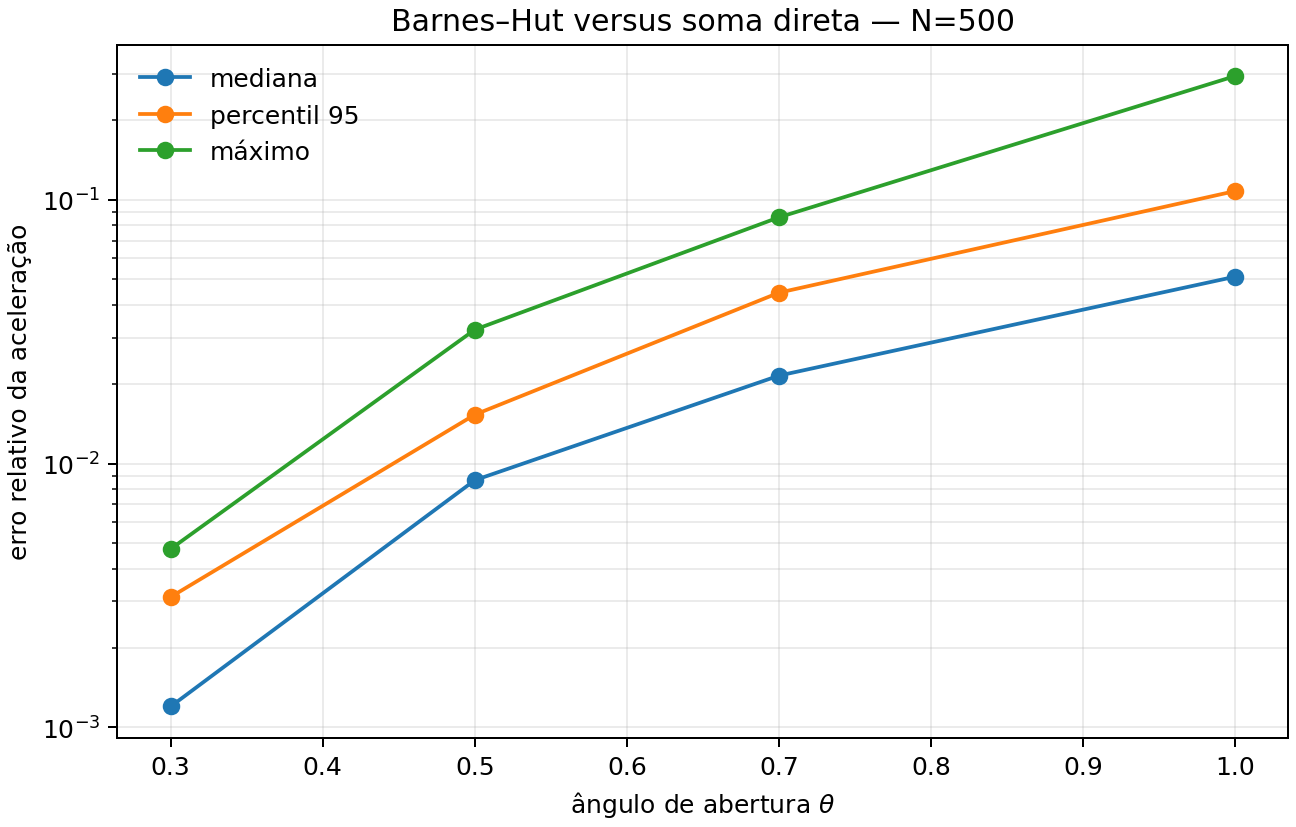

In [11]:
FORCE_VALIDATION_CFG = replace(DIRECT_CFG, n=500, t_end=1.0)
theta_values = (0.3, 0.5, 0.7, 1.0)
force_rows = force_comparison(FORCE_VALIDATION_CFG, theta_values)

print(f"{'theta':>6} {'mediana':>12} {'p95':>12} {'máximo':>12} {'tempo tree [s]':>16}")
for row in force_rows:
    print(
        f"{row['theta']:6.2f} {row['median']:12.4e} {row['p95']:12.4e} "
        f"{row['maximum']:12.4e} {row['tree_time']:16.4f}"
    )

theta = np.array([row["theta"] for row in force_rows])
median = np.array([row["median"] for row in force_rows])
p95 = np.array([row["p95"] for row in force_rows])
maximum = np.array([row["maximum"] for row in force_rows])

fig, ax = plt.subplots(figsize=(7.2, 4.6), constrained_layout=True)
ax.semilogy(theta, median, "o-", label="mediana")
ax.semilogy(theta, p95, "o-", label="percentil 95")
ax.semilogy(theta, maximum, "o-", label="máximo")
ax.set(
    xlabel=r"ângulo de abertura $\theta$",
    ylabel="erro relativo da aceleração",
    title=f"Barnes–Hut versus soma direta — N={FORCE_VALIDATION_CFG.n}",
)
ax.grid(alpha=0.25, which="both")
ax.legend(frameon=False)
plt.show()


Na validação realizada durante a construção deste notebook, \(\theta=0{,}5\) produziu erro mediano de aproximadamente **0,86%**, percentil 95 de **1,53%** e máximo de **3,22%**. É um bom ponto inicial, mas a escolha final deve considerar também conservação e tempo de execução.

## 10. Funções de execução, cache e diagnóstico


In [12]:
def summarize_result(result):
    cfg = json.loads(result["config_json"].item())
    method = result["method"].item()
    energy = result["energy"]
    lz = result["lz"]
    de = (energy[-1] - energy[0]) / abs(energy[0])
    dl = (lz[-1] - lz[0]) / abs(lz[0])
    print(f"método: {method}")
    print(f"N={cfg['n']}, epsilon={cfg['epsilon']}, theta={cfg['theta']}")
    print(f"runtime = {float(result['runtime']):.2f} s")
    print(f"deriva final de energia = {de:+.3e}")
    print(f"deriva final de Lz      = {dl:+.3e}")
    print("r10/r50/r90 inicial =", result["r_quantiles"][0].round(3), "kpc")
    print("r10/r50/r90 final   =", result["r_quantiles"][-1].round(3), "kpc")
    print(f"fração final r>20 kpc = {result['frac_gt20'][-1]:.4f}")


def run_or_load(cfg, method, path, overwrite=False):
    path = Path(path)
    if path.exists() and not overwrite:
        print("Carregando resultado existente:", path.name)
        result = load_result(path)
    else:
        print("Executando", method, "e salvando em", path.name)
        result = run_simulation(cfg, method, progress_every=100)
        save_result(result, path)
        print("Resultado salvo.")
    summarize_result(result)
    return result


def plot_result_dashboard(result, title=None):
    cfg = json.loads(result["config_json"].item())
    method = result["method"].item()
    time_values = result["time"]
    energy = result["energy"]
    lz = result["lz"]

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
    ax = axes[0, 0]
    ax.scatter(*result["positions"][0].T, s=2, alpha=0.55, label="inicial")
    ax.scatter(*result["positions"][-1].T, s=2, alpha=0.55, label="final")
    ax.set(xlim=(-20, 20), ylim=(-20, 20), aspect="equal", xlabel="x [kpc]", ylabel="y [kpc]")
    ax.legend(frameon=False, markerscale=3)

    ax = axes[0, 1]
    ax.plot(time_values, (energy - energy[0]) / abs(energy[0]), label="energia")
    ax.plot(time_values, (lz - lz[0]) / abs(lz[0]), label=r"$L_z$")
    ax.set(xlabel="tempo [Myr]", ylabel="erro relativo")
    ax.legend(frameon=False)

    ax = axes[1, 0]
    for i, label in enumerate(("r10", "r50", "r90")):
        ax.plot(time_values, result["r_quantiles"][:, i], label=label)
    ax.set(xlabel="tempo [Myr]", ylabel="raio [kpc]")
    ax.legend(frameon=False)

    ax = axes[1, 1]
    ax.plot(time_values, result["a1"], label=r"$A_1$")
    ax.plot(time_values, result["a2"], label=r"$A_2$")
    ax.plot(time_values, result["frac_gt20"], label=r"fração $r>20$ kpc")
    ax.set(xlabel="tempo [Myr]", ylabel="amplitude/fração")
    ax.legend(frameon=False)

    fig.suptitle(title or f"{method} — N={cfg['n']}")
    return fig


# Rota A — simulação com soma direta

Esta célula não depende do resultado Barnes–Hut. Para executar:

1. mude `EXECUTAR_DIRETO` para `True`;
2. execute somente esta célula;
3. volte o controle para `False`.

Se o arquivo já existir, ele será carregado. Use `SOBRESCREVER_DIRETO=True` apenas quando realmente quiser recalculá-lo.


In [ ]:
EXECUTAR_DIRETO = False
SOBRESCREVER_DIRETO = False

direct_result = load_result(DIRECT_RESULT_PATH) if DIRECT_RESULT_PATH.exists() else None

if EXECUTAR_DIRETO:
    direct_result = run_or_load(
        DIRECT_CFG,
        "direct",
        DIRECT_RESULT_PATH,
        overwrite=SOBRESCREVER_DIRETO,
    )
else:
    print("Soma direta não executada.")
    print("Arquivo esperado:", DIRECT_RESULT_PATH)


Soma direta não executada.


In [ ]:
PLOTAR_DIRETO = False

if PLOTAR_DIRETO:
    if not DIRECT_RESULT_PATH.exists():
        raise FileNotFoundError("Execute ou selecione um resultado direto primeiro.")
    direct_result = load_result(DIRECT_RESULT_PATH)
    fig = plot_result_dashboard(direct_result, "Soma direta")
    fig.savefig(OUTPUT_DIR / "diagnostico_direto.png", dpi=160)
    plt.show()


# Rota B — simulação Barnes–Hut

Esta célula é independente da soma direta. Você pode mudar `TREE_CFG.n`, `epsilon` ou `theta`, executar o Tree Code e manter todos os resultados diretos já salvos.

Para uma comparação metodológica justa, use `TREE_CFG = TREE_VALIDATION_CFG`. Para alta resolução, use `TREE_HIGHRES_CFG`.


In [ ]:
EXECUTAR_TREE = False
SOBRESCREVER_TREE = False

tree_result = load_result(TREE_RESULT_PATH) if TREE_RESULT_PATH.exists() else None

if EXECUTAR_TREE:
    tree_result = run_or_load(
        TREE_CFG,
        "tree",
        TREE_RESULT_PATH,
        overwrite=SOBRESCREVER_TREE,
    )
else:
    print("Tree Code não executado.")
    print("Arquivo esperado:", TREE_RESULT_PATH)


Tree Code não executado.


In [ ]:
PLOTAR_TREE = False

if PLOTAR_TREE:
    if not TREE_RESULT_PATH.exists():
        raise FileNotFoundError("Execute ou selecione um resultado Tree primeiro.")
    tree_result = load_result(TREE_RESULT_PATH)
    fig = plot_result_dashboard(tree_result, "Barnes–Hut Tree Code")
    fig.savefig(OUTPUT_DIR / "diagnostico_tree.png", dpi=160)
    plt.show()


# GIFs independentes

Os GIFs abaixo **não executam forças nem integração temporal**. Eles utilizam exclusivamente os arquivos `.npz` selecionados.

- GIF 1: somente soma direta;
- GIF 2: somente Barnes–Hut;
- GIF 3: comparação em duas colunas.

Você pode apontar `DIRECT_RESULT_FOR_GIF` e `TREE_RESULT_FOR_GIF` para quaisquer resultados previamente salvos.


In [13]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display


DIRECT_RESULT_FOR_GIF = DIRECT_RESULT_PATH
TREE_RESULT_FOR_GIF = TREE_RESULT_PATH


def _result_label(result):
    cfg = json.loads(result["config_json"].item())
    method = result["method"].item()
    if method == "direct":
        return f"Soma direta — N={cfg['n']}"
    return f"Barnes–Hut — N={cfg['n']}, theta={cfg['theta']}"


def _point_size(n):
    return float(np.clip(8000.0 / n, 0.45, 6.0))


def make_single_gif(result_path, gif_path, color="#8bd3ff", max_frames=101, lim=20.0):
    result = load_result(result_path)
    positions = result["positions"]
    times = result["time"]
    frame_ids = np.linspace(0, len(times) - 1, min(max_frames, len(times)), dtype=int)

    fig, ax = plt.subplots(figsize=(6.2, 6.2), constrained_layout=True)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", xlabel="x [kpc]", ylabel="y [kpc]")
    ax.set_title(_result_label(result))
    ax.set_facecolor("#050814")
    scatter = ax.scatter([], [], s=_point_size(positions.shape[1]), c=color, alpha=0.8, edgecolors="none")
    clock = ax.text(0.03, 0.96, "", transform=ax.transAxes, color="white", va="top")

    def update(frame_index):
        k = frame_ids[frame_index]
        scatter.set_offsets(positions[k])
        clock.set_text(f"t = {times[k]:.0f} Myr")
        return scatter, clock

    anim = FuncAnimation(fig, update, frames=len(frame_ids), interval=50, blit=True, repeat=True)
    anim.save(gif_path, writer=PillowWriter(fps=20), dpi=100)
    plt.close(fig)
    return Path(gif_path)


def make_comparison_gif(direct_path, tree_path, gif_path, max_frames=101, lim=20.0):
    direct = load_result(direct_path)
    tree = load_result(tree_path)
    results = (direct, tree)
    n_frames = min(max_frames, len(direct["time"]), len(tree["time"]))
    frame_ids = [
        np.linspace(0, len(result["time"]) - 1, n_frames, dtype=int)
        for result in results
    ]

    fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
    scatters, clocks = [], []
    colors = ("#8bd3ff", "#fbbf24")
    for ax, result, color in zip(axes, results, colors):
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", xlabel="x [kpc]", ylabel="y [kpc]")
        ax.set_title(_result_label(result))
        ax.set_facecolor("#050814")
        scatters.append(ax.scatter([], [], s=_point_size(result["positions"].shape[1]), c=color, alpha=0.78, edgecolors="none"))
        clocks.append(ax.text(0.03, 0.96, "", transform=ax.transAxes, color="white", va="top"))

    def update(frame_index):
        artists = []
        for k, result, ids, scatter, clock in zip(range(2), results, frame_ids, scatters, clocks):
            index = ids[frame_index]
            scatter.set_offsets(result["positions"][index])
            clock.set_text(f"t = {result['time'][index]:.0f} Myr")
            artists.extend((scatter, clock))
        return tuple(artists)

    anim = FuncAnimation(fig, update, frames=n_frames, interval=50, blit=True, repeat=True)
    anim.save(gif_path, writer=PillowWriter(fps=20), dpi=100)
    plt.close(fig)
    return Path(gif_path)


## GIF 1 — somente soma direta


In [ ]:
GERAR_GIF_DIRETO = False
GIF_DIRETO_PATH = OUTPUT_DIR / "galaxia_soma_direta.gif"

if GERAR_GIF_DIRETO:
    if not Path(DIRECT_RESULT_FOR_GIF).exists():
        raise FileNotFoundError(DIRECT_RESULT_FOR_GIF)
    make_single_gif(DIRECT_RESULT_FOR_GIF, GIF_DIRETO_PATH, color="#8bd3ff")
    display(Image(filename=str(GIF_DIRETO_PATH)))
else:
    print("GIF direto não solicitado.")


GIF direto não solicitado.


## GIF 2 — somente Barnes–Hut


In [ ]:
GERAR_GIF_TREE = False
GIF_TREE_PATH = OUTPUT_DIR / "galaxia_barnes_hut.gif"

if GERAR_GIF_TREE:
    if not Path(TREE_RESULT_FOR_GIF).exists():
        raise FileNotFoundError(TREE_RESULT_FOR_GIF)
    make_single_gif(TREE_RESULT_FOR_GIF, GIF_TREE_PATH, color="#fbbf24")
    display(Image(filename=str(GIF_TREE_PATH)))
else:
    print("GIF Tree não solicitado.")


GIF Tree não solicitado.


## GIF 3 — comparação em duas colunas


In [ ]:
GERAR_GIF_COMPARATIVO = False
GIF_COMPARATIVO_PATH = OUTPUT_DIR / "comparacao_direta_vs_barnes_hut.gif"

if GERAR_GIF_COMPARATIVO:
    if not Path(DIRECT_RESULT_FOR_GIF).exists():
        raise FileNotFoundError(DIRECT_RESULT_FOR_GIF)
    if not Path(TREE_RESULT_FOR_GIF).exists():
        raise FileNotFoundError(TREE_RESULT_FOR_GIF)
    make_comparison_gif(
        DIRECT_RESULT_FOR_GIF,
        TREE_RESULT_FOR_GIF,
        GIF_COMPARATIVO_PATH,
    )
    display(Image(filename=str(GIF_COMPARATIVO_PATH)))
else:
    print("GIF comparativo não solicitado.")


GIF comparativo não solicitado.


In [ ]:
# No Colab, ative somente os downloads desejados.
BAIXAR_GIF_DIRETO = False
BAIXAR_GIF_TREE = False
BAIXAR_GIF_COMPARATIVO = False

if any((BAIXAR_GIF_DIRETO, BAIXAR_GIF_TREE, BAIXAR_GIF_COMPARATIVO)):
    from google.colab import files
    if BAIXAR_GIF_DIRETO:
        files.download(str(GIF_DIRETO_PATH))
    if BAIXAR_GIF_TREE:
        files.download(str(GIF_TREE_PATH))
    if BAIXAR_GIF_COMPARATIVO:
        files.download(str(GIF_COMPARATIVO_PATH))


## 11. Benchmark opcional de escalabilidade

Este benchmark realiza apenas **uma avaliação de força** para cada \(N\). Ele não recalcula as simulações salvas. A soma direta é limitada a valores menores de \(N\), enquanto o Tree Code pode continuar até 20.000 partículas.


In [14]:
def benchmark_scaling(
    direct_sizes=(500, 1500, 3000),
    tree_sizes=(500, 1500, 5000, 10000, 20000),
    repeats=2,
):
    direct_times = []
    tree_times = []

    for n in direct_sizes:
        cfg = replace(DIRECT_CFG, n=n, t_end=1.0)
        pos, _ = sample_exponential_disk(cfg)
        mass = cfg.m_disk / cfg.n
        measurements = []
        for _ in range(repeats):
            start = time.perf_counter()
            direct_disk_force(pos, mass, cfg.epsilon)
            measurements.append(time.perf_counter() - start)
        direct_times.append(min(measurements))
        print("direct", n, direct_times[-1])

    for n in tree_sizes:
        cfg = replace(TREE_HIGHRES_CFG, n=n, t_end=1.0)
        pos, _ = sample_exponential_disk(cfg)
        mass = cfg.m_disk / cfg.n
        measurements = []
        for _ in range(repeats):
            start = time.perf_counter()
            tree_disk_force(pos, mass, cfg.epsilon, cfg.theta, cfg.bucket_capacity, cfg.max_depth)
            measurements.append(time.perf_counter() - start)
        tree_times.append(min(measurements))
        print("tree", n, tree_times[-1])

    fig, ax = plt.subplots(figsize=(7.2, 4.8), constrained_layout=True)
    ax.loglog(direct_sizes, direct_times, "o-", label="soma direta")
    ax.loglog(tree_sizes, tree_times, "o-", label="Barnes–Hut")
    ax.set(xlabel="número de partículas N", ylabel="tempo de uma força [s]", title="Escalabilidade")
    ax.grid(alpha=0.25, which="both")
    ax.legend(frameon=False)
    return {
        "direct_sizes": np.asarray(direct_sizes),
        "direct_times": np.asarray(direct_times),
        "tree_sizes": np.asarray(tree_sizes),
        "tree_times": np.asarray(tree_times),
        "figure": fig,
    }


In [ ]:
RUN_SCALING_BENCHMARK = False

if RUN_SCALING_BENCHMARK:
    benchmark = benchmark_scaling()
    benchmark["figure"].savefig(OUTPUT_DIR / "benchmark_escalabilidade.png", dpi=160)
    plt.show()
else:
    print("Benchmark não executado.")


Benchmark não executado.


## 12. Como interpretar comparações

Há dois tipos diferentes de comparação:

### Validação do método

Use o mesmo \(N\), \(\epsilon\), passo temporal e semente:

```python
TREE_CFG = TREE_VALIDATION_CFG
```

Assim, diferenças vêm principalmente da aproximação Barnes–Hut.

### Ganho de resolução

Compare a referência direta com 1.500 partículas e o Tree Code com 10.000 ou mais partículas. Essa comparação mostra o efeito combinado de método, resolução e softening; não deve ser interpretada como erro puro do algoritmo.

O notebook seguinte poderá utilizar o Tree Code validado para os encontros galácticos de controle, prógrado e retrógrado, sem modificar este histórico.
